# 02 · Local Kalman filter + Phase-1 baseline
Rubric items: *Theoretical Rigor*, *Technical Validation*, *Hybrid Innovation (input)*

Phase 1 was ML-only. For a **fair** Phase-2 comparison we re-run the three Phase-1 models on exactly the same
300 SKUs, the same three rolling origins and the same metrics as the deep models:

| model | type | uncertainty |
|---|---|---|
| Seasonal naive (weekly) | local, no learning | empirical residual quantiles |
| LightGBM with lag features | global tabular ML | separate quantile-loss models |
| **Kalman filter** (local level × weekday profile) | local state-space | Gaussian predictive variance |

The Kalman filter also produces the **states used by the hybrid model** in notebook 04.

In [1]:
%run ./00_common.ipynb
import lightgbm as lgb
from scipy.stats import norm

P = load_panel()
Y, STOCK, N, T = P["Y"], P["STOCK"], P["N"], P["T"]
dow = P["dow"]
meta = P["meta"]
FIT_END = ORIGINS["O1"] - H          # parameters are estimated only on data before every validation/test window
Z_Q = {q: norm.ppf(q) for q in QUANTILES}

common loaded | ROOT=/Users/Harsh/Downloads/inventory-demand-forecasting 2 | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 1. Seasonal naive
$\hat y_{o+h} = y_{o+h-7k}$ (same weekday last week). Quantiles = point + empirical quantiles of the weekly
differences $y_t - y_{t-7}$ over the last 26 weeks, clipped at 0.

In [2]:
def seasonal_naive(origin_name, o):
    rows = []
    for i in range(N):
        last_week = Y[i, o - 6:o + 1]
        fallback = np.nanmean(Y[i, o - 27:o + 1]) if np.any(~np.isnan(Y[i, o - 27:o + 1])) else 0.0
        last_week = np.where(np.isnan(last_week), fallback, last_week)
        point = np.array([last_week[(h - 1) % 7] for h in range(1, H + 1)])
        hist = Y[i, o - 181:o + 1]
        res = (hist[7:] - hist[:-7]); res = res[~np.isnan(res)]
        if len(res) == 0:
            res = np.zeros(1)
        r = dict(model="seasonal_naive", origin=origin_name, sidx=i, h=np.arange(1, H + 1), t=o + np.arange(1, H + 1), mean=point)
        for q in QUANTILES:
            r[f"q{int(q*100)}"] = np.clip(point + np.quantile(res, q), 0, None)
        rows.append(pd.DataFrame(r))
    return pd.concat(rows)


snaive = pd.concat([seasonal_naive(k, o) for k, o in ORIGINS.items()], ignore_index=True)
snaive.to_parquet(FC / "seasonal_naive.parquet")
score(attach_actuals(snaive, P))

MAE            1.577421
RMSE           3.342422
WAPE           0.756888
Pinball        0.513706
Cov80          0.843016
Width80        3.863365
n          25200.000000
dtype: float64

## 2. LightGBM with lag features (direct 28-day model, no peeking)
All lags are **≥ 28 days**, so one model can forecast every day of the 28-day horizon without recursion and
without ever using a value after the origin. Mean model: Tweedie objective (count-like data);
interval models: quantile (pinball) objective for τ = 0.1, 0.5, 0.9. Stockout days are dropped from the training targets.

In [3]:
def lag_features():
    Yf = pd.DataFrame(Y.T)                                   # (T, N), NaN = not on sale
    feats = {}
    for L in (28, 35, 42, 49, 56):
        feats[f"lag_{L}"] = Yf.shift(L).values.T
    sh = Yf.shift(28)
    feats["rmean7_28"] = sh.rolling(7, min_periods=1).mean().values.T
    feats["rmean28_28"] = sh.rolling(28, min_periods=1).mean().values.T
    feats["rstd28_28"] = sh.rolling(28, min_periods=2).std().values.T
    month = pd.to_datetime(P["dates"]).month.values
    df = pd.DataFrame({k: v.ravel() for k, v in feats.items()})
    df["sidx"] = np.repeat(np.arange(N), T); df["t"] = np.tile(np.arange(T), N)
    df["dow"] = np.tile(dow, N); df["month"] = np.tile(month, N)
    for j, name in enumerate(P["cov_names"]):
        if name in ("snap", "event", "rel_price", "age"):
            df[name] = P["X"][:, :, j].ravel()
    df["item"] = meta["item_idx"].values[df["sidx"]]
    df["dept"] = meta["dept_idx"].values[df["sidx"]]
    df["y"] = Y.ravel(); df["stock"] = STOCK.ravel()
    return df


tab = lag_features()
FEATS = [c for c in tab.columns if c not in ("sidx", "t", "y", "stock")]
print(len(FEATS), "features:", FEATS)

16 features: ['lag_28', 'lag_35', 'lag_42', 'lag_49', 'lag_56', 'rmean7_28', 'rmean28_28', 'rstd28_28', 'dow', 'month', 'snap', 'event', 'rel_price', 'age', 'item', 'dept']


In [4]:
# macOS: LightGBM (Homebrew libomp) and PyTorch (bundled libomp) load two different OpenMP runtimes.
# Once torch is imported, multi-threaded LightGBM segfaults ("Kernel died"), and KMP_DUPLICATE_LIB_OK does
# not prevent it. A single LightGBM thread (in train AND predict) never starts an OpenMP pool, so it is safe. Other platforms: all cores.
import sys
LGB_THREADS = 1 if sys.platform == "darwin" else 0   # 0 = LightGBM default (all cores)
LGB_PARAMS = dict(learning_rate=0.05, num_leaves=31, min_data_in_leaf=50, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=CFG["seed"],
                  num_threads=LGB_THREADS)
lgb_frames = []
for name, o in ORIGINS.items():
    tr = tab[(tab.t >= 60) & (tab.t <= o) & tab.y.notna() & (tab.stock == 0)]
    te = tab[(tab.t > o) & (tab.t <= o + H)]
    out = te[["sidx", "t"]].copy(); out["model"] = "lightgbm"; out["origin"] = name; out["h"] = out.t - o
    ds = lgb.Dataset(tr[FEATS], tr.y, categorical_feature=["item", "dept"], free_raw_data=False)
    m = lgb.train({**LGB_PARAMS, "objective": "tweedie", "tweedie_variance_power": 1.2}, ds, 400)
    out["mean"] = np.clip(m.predict(te[FEATS], num_threads=LGB_THREADS), 0, None)
    for q in QUANTILES:
        mq = lgb.train({**LGB_PARAMS, "objective": "quantile", "alpha": q}, ds, 400)
        out[f"q{int(q*100)}"] = np.clip(mq.predict(te[FEATS], num_threads=LGB_THREADS), 0, None)
    # quantile models are fitted separately -> enforce non-crossing q10 <= q50 <= q90
    out[["q10", "q50", "q90"]] = np.sort(out[["q10", "q50", "q90"]].values, axis=1)
    lgb_frames.append(out)
    print(name, "train rows:", len(tr))
lgbm = pd.concat(lgb_frames, ignore_index=True)
lgbm.to_parquet(FC / "lightgbm.parquet")
score(attach_actuals(lgbm, P))

O1 train rows: 221913


O2 train rows: 229750


O3 train rows: 237583


MAE            1.361466
RMSE           2.664696
WAPE           0.653267
Pinball        0.402583
Cov80          0.801548
Width80        4.009974
n          25200.000000
dtype: float64

## 3. Kalman filter (Kalman, 1960) — theory
**State-space model** (per SKU, after dividing by the weekday profile $s_{dow}$):

$$x_t = x_{t-1} + w_t,\;\; w_t\sim\mathcal N(0,q) \qquad\qquad z_t = y_t/s_{dow(t)} = x_t + v_t,\;\; v_t\sim\mathcal N(0,r)$$

**Why the gain is optimal.** Given $\hat x_{t|t-1}$ with error variance $P_{t|t-1}$, the update
$\hat x_{t|t}=\hat x_{t|t-1}+K(z_t-\hat x_{t|t-1})$ has error variance $(1-K)^2P_{t|t-1}+K^2r$.
Setting the derivative w.r.t. $K$ to zero gives $K=P_{t|t-1}/(P_{t|t-1}+r)$ — the minimum-variance (MMSE) linear estimator,
and $P_{t|t}=(1-K)P_{t|t-1}$.

* **Large $q/r$** → gain near 1 → the level follows the data quickly (adaptive, noisy).
* **Small $q/r$** → gain near 0 → long moving average (smooth, slow).

**Parameter estimation.** The innovations $v_t=z_t-\hat x_{t|t-1}$ are independent $\mathcal N(0,F_t)$, so the
log-likelihood is $-\tfrac12\sum_t(\log 2\pi F_t + v_t^2/F_t)$ (prediction-error decomposition). With $q=\rho r$,
$r$ has the closed form $\hat r=\frac1n\sum v_t^2/F_t^*$, and we pick $\rho$ on a log grid.

**h-step forecast:** $\hat y_{o+h}=s_{dow}\hat x_{o|o}$, variance $s_{dow}^2(P_{o|o}+hq+r)$ — uncertainty grows linearly in $h$.

**Stockouts:** the observation is treated as *missing*: predict step only, no update.

The code lives in Section C of `00_common` (`kalman_local_level`, `fit_kalman_series`).

In [5]:
t_start = time.time()
params = []
for i in range(N):
    y_fit = Y[i].copy()
    y_fit[STOCK[i] == 1] = np.nan                     # stockouts are missing observations
    params.append(fit_kalman_series(y_fit, dow, FIT_END))
print(f"fitted {N} filters in {time.time()-t_start:.1f}s")

rho = np.array([p["rho"] for p in params]); sigma2 = np.array([p["sigma2"] for p in params])
PROF = np.stack([p["prof"] for p in params])
print(pd.Series(rho).describe()[["min", "25%", "50%", "75%", "max"]].round(4))

fitted 300 filters in 3.5s
min    0.0001
25%    0.0001
50%    0.0006
75%    0.0032
max    0.1778
dtype: float64


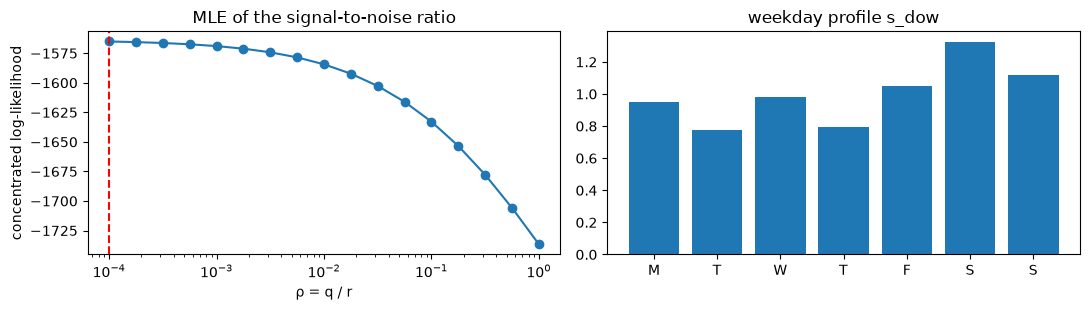

In [6]:
i_demo = int(meta.index[meta.dept_id == "FOODS_3"][0])
y_demo = Y[i_demo].copy(); y_demo[STOCK[i_demo] == 1] = np.nan
z_demo = y_demo[:FIT_END + 1] / PROF[i_demo][dow[:FIT_END + 1]]
lls = [concentrated_loglik(*kalman_local_level(z_demo, r_)[2:])[0] for r_ in RHO_GRID]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].semilogx(RHO_GRID, lls, marker="o"); ax[0].axvline(rho[i_demo], c="red", ls="--")
ax[0].set_xlabel("ρ = q / r"); ax[0].set_ylabel("concentrated log-likelihood"); ax[0].set_title("MLE of the signal-to-noise ratio")
ax[1].bar(range(7), PROF[i_demo]); ax[1].set_xticks(range(7)); ax[1].set_xticklabels(list("MTWTFSS"))
ax[1].set_title("weekday profile s_dow"); plt.tight_layout(); plt.savefig(FIG / "02_kalman_mle.png", dpi=150); plt.show()

### Run the filter over the full panel (causal) and save the states for the hybrid model

In [7]:
LEVEL = np.full((N, T), np.nan); PV = np.full((N, T), np.nan); INNOV = np.full((N, T), np.nan)
for i in range(N):
    y_i = Y[i].copy(); y_i[STOCK[i] == 1] = np.nan
    x, Pv, v, Fv = kalman_local_level(y_i / PROF[i][dow], rho[i])
    LEVEL[i], PV[i] = x, Pv * sigma2[i]
    INNOV[i] = v / np.sqrt(Fv)                       # standardised innovations (unit variance)
Qn, Rn = rho * sigma2, sigma2
np.savez_compressed(PROC / "kalman_states.npz", level=LEVEL, P=PV, prof=PROF, dow=dow, q=Qn, r=Rn, rho=rho)

**Diagnostic (technical validation).** If the model is adequate, standardised innovations have variance ≈ 1.

median std of standardised innovations: 1.247


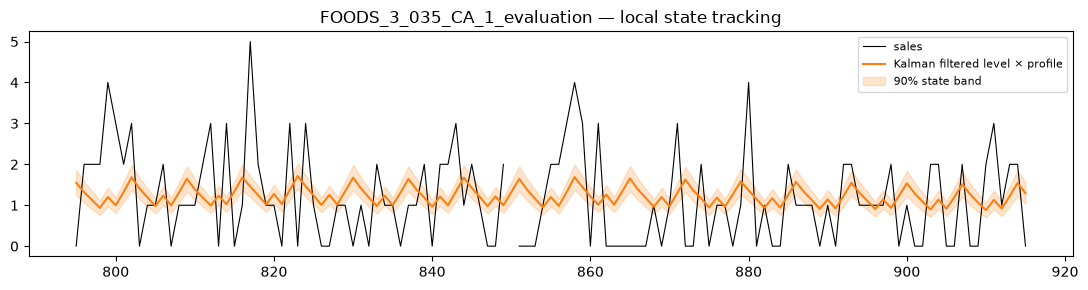

In [8]:
ok = ~np.isnan(INNOV[:, :FIT_END])
std_innov = np.array([np.nanstd(INNOV[i, :FIT_END]) for i in range(N)])
print("median std of standardised innovations:", np.nanmedian(std_innov).round(3))

fig, ax = plt.subplots(figsize=(11, 3))
tt = np.arange(ORIGINS["O1"] - 120, ORIGINS["O1"] + 1)
ax.plot(tt, Y[i_demo, tt], color="black", lw=0.8, label="sales")
ax.plot(tt, LEVEL[i_demo, tt] * PROF[i_demo][dow[tt]], color="C1", label="Kalman filtered level × profile")
band = PROF[i_demo][dow[tt]] * np.sqrt(PV[i_demo, tt])
ax.fill_between(tt, (LEVEL[i_demo, tt] - 1.64 * np.sqrt(PV[i_demo, tt])) * PROF[i_demo][dow[tt]],
                (LEVEL[i_demo, tt] + 1.64 * np.sqrt(PV[i_demo, tt])) * PROF[i_demo][dow[tt]], alpha=0.2, color="C1", label="90% state band")
ax.legend(fontsize=8); ax.set_title(f"{meta.id[i_demo]} — local state tracking")
plt.tight_layout(); plt.savefig(FIG / "02_kalman_tracking.png", dpi=150); plt.show()

### Kalman forecasts at each rolling origin

In [9]:
kf_frames = []
for name, o in ORIGINS.items():
    for i in range(N):
        hh = np.arange(1, H + 1); tt = o + hh
        lvl = LEVEL[i, o] if not np.isnan(LEVEL[i, o]) else 0.0
        mean, sd = kalman_forecast(lvl, np.nan_to_num(PV[i, o]), PROF[i], dow[tt], Qn[i], Rn[i], hh)
        r = dict(model="kalman", origin=name, sidx=i, h=hh, t=tt, mean=np.clip(mean, 0, None))
        for q in QUANTILES:
            r[f"q{int(q*100)}"] = np.clip(mean + Z_Q[q] * sd, 0, None)
        kf_frames.append(pd.DataFrame(r))
kalman = pd.concat(kf_frames, ignore_index=True)
kalman.to_parquet(FC / "kalman.parquet")
score(attach_actuals(kalman, P))

MAE            1.324615
RMSE           2.571057
WAPE           0.635585
Pinball        0.415777
Cov80          0.869841
Width80        4.028782
n          25200.000000
dtype: float64

## 4. Identifying the gap
### 4a. Accuracy by demand segment

In [10]:
allbase = pd.concat([snaive, lgbm, kalman], ignore_index=True)
allbase = attach_actuals(allbase, P)
seg_tab = allbase.groupby(["segment", "model"]).apply(score)[["WAPE", "Pinball", "Cov80"]].unstack("model").round(3)
seg_tab

WAPE                         Pinball                          \
model        kalman lightgbm seasonal_naive  kalman lightgbm seasonal_naive   
segment                                                                       
erratic       0.739    0.759          0.935   1.584    1.522          2.003   
intermittent  0.801    0.818          0.920   0.235    0.226          0.287   
lumpy         0.951    0.961          1.057   0.510    0.471          0.624   
smooth        0.377    0.397          0.480   0.870    0.891          1.090   

              Cov80                          
model        kalman lightgbm seasonal_naive  
segment                                      
erratic       0.820    0.715          0.805  
intermittent  0.871    0.814          0.857  
lumpy         0.920    0.785          0.810  
smooth        0.812    0.785          0.827

### 4b. Local filters cannot share seasonal patterns across sparse histories
Each Kalman filter estimates its own weekday profile from its *own* history only. We test what happens when that
history is short (like a new or sparse product).

**Experiment.** At each origin, estimate the weekday profile from either the **full** training history or only the
**last 8 weeks**, and either from the SKU **alone** ("own") or **pooled over all SKUs of its department** (the simplest
possible form of cross-series sharing). The level is the same Kalman level in all four cases; we compare test WAPE.

In [11]:
def pooled_profiles(t_from, t_to):
    out = {}
    for d, g in meta.groupby("dept_id"):
        yy = np.where(STOCK[g.index, t_from:t_to] == 1, np.nan, Y[g.index, t_from:t_to])
        with np.errstate(invalid="ignore", divide="ignore"):
            yy = yy / np.nanmean(yy, axis=1, keepdims=True)     # normalise each SKU, then average
        prof_d = np.array([np.nanmean(yy[:, dow[t_from:t_to] == k]) for k in range(7)])
        out[d] = prof_d / prof_d.mean()
    return out


rows = []
for name, o in ORIGINS.items():
    for hist_name, t_from in (("full history", 0), ("last 8 weeks", o - 55)):
        pooled = pooled_profiles(t_from, o + 1)
        for i in range(N):
            hh = np.arange(1, H + 1); tt = o + hh
            lvl = np.nan_to_num(LEVEL[i, o])
            y_hist = np.where(STOCK[i, t_from:o + 1] == 1, np.nan, Y[i, t_from:o + 1])
            own = dow_profile(y_hist, dow[t_from:o + 1])
            for kind, prof in (("own", own), ("dept-pooled", pooled[meta.dept_id[i]])):
                rows.append(pd.DataFrame(dict(history=hist_name, kind=kind, sidx=i, t=tt,
                                              mean=np.clip(prof[dow[tt]] * lvl, 0, None))))
cmp_ = pd.concat(rows)
cmp_["y"] = Y[cmp_.sidx, cmp_.t]; cmp_["segment"] = meta.segment.values[cmp_.sidx]
cmp_ = cmp_[cmp_.y.notna()]
gap = (cmp_.groupby(["history", "segment", "kind"])
       .apply(lambda g: np.abs(g.y - g["mean"]).sum() / g.y.sum()).unstack().round(4))
gap["gain from sharing (%)"] = (100 * (gap["own"] - gap["dept-pooled"]) / gap["own"]).round(2)
gap.to_csv(TAB / "02_gap_profile_sharing.csv")
gap

kind                       dept-pooled     own  gain from sharing (%)
history      segment                                                 
full history erratic            0.7375  0.7388                   0.18
             intermittent       0.8030  0.8011                  -0.24
             lumpy              0.9519  0.9507                  -0.13
             smooth             0.3803  0.3762                  -1.09
last 8 weeks erratic            0.7449  0.7468                   0.25
             intermittent       0.8055  0.8137                   1.01
             lumpy              0.9517  0.9599                   0.85
             smooth             0.3851  0.3923                   1.84

**Reading the table.** With ~2.5 years of history the own profile is already good (shrinkage helps sparse items),
so pooling changes little. With only 8 weeks the own profile is noisy and pooling across the department improves
WAPE — i.e. **the information needed is in the other series, and a local filter cannot use it**.
A global model learns such shared patterns automatically (and also event / SNAP / price effects that the Kalman
filter has no input for).

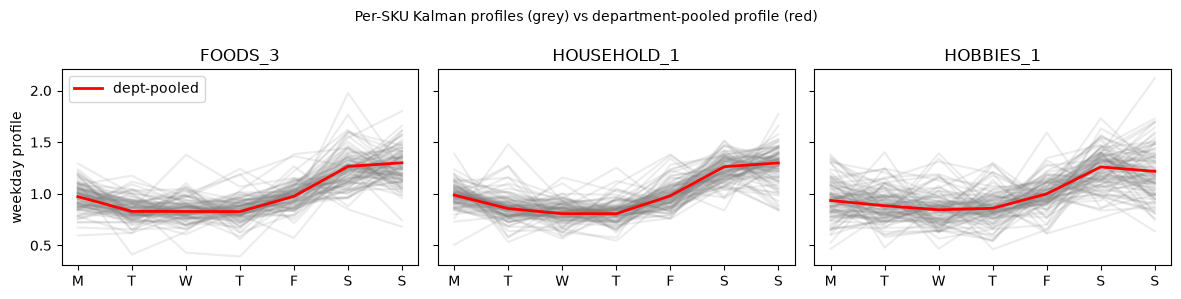

In [12]:
pooled_full = pooled_profiles(0, FIT_END + 1)
fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for k, d in enumerate(CFG["depts"]):
    idx = meta.index[meta.dept_id == d]
    ax[k].plot(PROF[idx].T, color="grey", alpha=0.15)
    ax[k].plot(pooled_full[d], color="red", lw=2, label="dept-pooled")
    ax[k].set_xticks(range(7)); ax[k].set_xticklabels(list("MTWTFSS")); ax[k].set_title(d)
ax[0].set_ylabel("weekday profile"); ax[0].legend()
plt.suptitle("Per-SKU Kalman profiles (grey) vs department-pooled profile (red)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "02_profiles_gap.png", dpi=150); plt.show()

### 4c. Summary of the gap
* The Kalman filter **adapts quickly** to level changes (and handles stockouts as missing data naturally) but
  it is purely **local**: every SKU learns its own weekday pattern, has no notion of events/SNAP/price, and its
  variance grows only with $h$.
* Sparse SKUs (HOBBIES, intermittent/lumpy segments) have too little data to learn seasonality alone.
* LightGBM is global, but only gives point/quantile regressions per day — no coherent sample paths and it
  needs hand-made lag features (lag ≥ 28 to avoid peeking, so it ignores the most recent 27 days).

→ **Phase 2** trains a *global* probabilistic deep model (DeepAR, notebook 03) and then a **hybrid** that feeds
the Kalman state into DeepAR (notebook 04), keeping fast local adaptation *and* shared seasonal learning.